# Titanic Project

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [42]:
sns.set_theme(style="whitegrid")
passengers = sns.load_dataset("titanic")
passengers.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [43]:
passengers.shape

(891, 15)

In [44]:
passengers.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [45]:
passengers.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [46]:
passengers = passengers.drop(columns=["deck"])
passengers.shape

(891, 14)

In [47]:
passengers = passengers.dropna(subset=["embarked", "embark_town"])

In [48]:
passengers.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
embark_town      0
alive            0
alone            0
dtype: int64

In [49]:
print(passengers["age"].mean())
print(passengers["age"].median())

29.64209269662921
28.0


In [50]:
passengers["age"] = passengers["age"].fillna(passengers["age"].median())
passengers.isna().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64

In [51]:
passengers = passengers.rename(columns={"pclass":"passenger_class"})
passengers.head()

,survived,passenger_class,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [52]:
passengers = passengers.rename(columns={"sibsp":"siblings_spouses"})
passengers.head()

,survived,passenger_class,sex,age,siblings_spouses,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True


In [53]:
passengers["survived"].mean()

np.float64(0.38245219347581555)

In [54]:
passengers.groupby("sex")["survived"].mean()

sex
female    0.740385
male      0.188908
Name: survived, dtype: float64

In [55]:
passengers.groupby("class")["survived"].mean()

class
First     0.626168
Second    0.472826
Third     0.242363
Name: survived, dtype: float64

In [56]:
passengers.groupby(["sex", "class"])["survived"].mean().round(2)

sex     class 
female  First     0.97
        Second    0.92
        Third     0.50
male    First     0.37
        Second    0.16
        Third     0.14
Name: survived, dtype: float64

In [60]:
passengers["is_child"] = np.where(passengers["age"] < 12, "child", "adult")
passengers.head()

,survived,passenger_class,sex,age,siblings_spouses,parch,fare,embarked,class,who,adult_male,embark_town,alive,alone,is_child
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,Southampton,no,False,adult
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,Cherbourg,yes,False,adult
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,Southampton,yes,True,adult
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,Southampton,yes,False,adult
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,Southampton,no,True,adult


In [61]:
passengers.groupby("is_child")["survived"].mean()

is_child
adult    0.366626
child    0.573529
Name: survived, dtype: float64

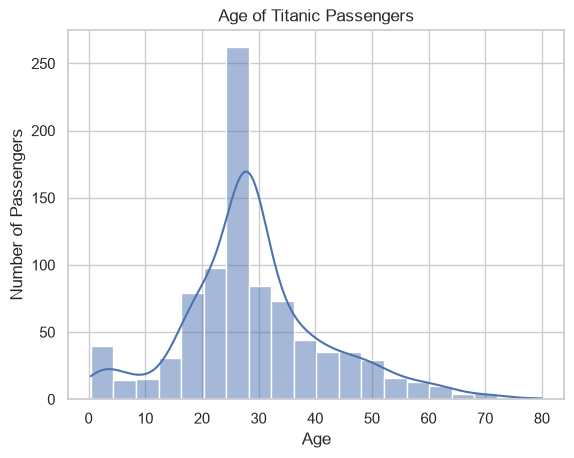

In [62]:
sns.histplot(data=passengers, x="age", bins=20, kde=True)
plt.title("Age of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()